# Dataset 1 for analysis/demonstration

## Part 1: Test set (10%) MSE Comparsion for 30% (aug), 60%(non-aug/ "true"), 90% (all training) 

In [1]:
import json

with open(file="C:/Users/bandarua/crda_gp/data/steels_yield.json") as file:
    data = json.load(file)

data.keys()

dict_keys(['index', 'columns', 'data'])

In [2]:
import numpy as np
data_array = np.array(data['data'])

In [3]:
# Composition and yield dictionary
my_data = {}
for i in range(len(data['columns'])):
    my_data[data['columns'][i]] = []
    for j in range(len(data['data'])):
        my_data[data['columns'][i]].append(data['data'][j][i])

In [4]:
import re
my_data['split_composition'] = []
for composition in my_data['composition']:
    matches = re.findall(r'([A-Z][a-z]?)(\d*\.?\d+)', composition)
    my_data['split_composition'].append({element: float(value) for element, value in matches})
# my_data['split_composition']

In [5]:
# Get the keys
key_count = []
for key in my_data['split_composition']:
    # print(f"Key: {key.keys()}")
    # print(f"Key Length: {len(key.keys())}")
    key_count.append(key.keys())
keys = list(max(key_count))

In [6]:
composition_dict = {}

for key in keys:
    composition_dict[key] = []
    for comp in my_data['split_composition']:
        if key in list(comp.keys()):
            composition_dict[key].append(comp[key])
        else:
            composition_dict[key].append(0)

In [7]:
import pandas as pd
df = pd.DataFrame(data=composition_dict)
df

,Fe,C,Mn,Si,Cr,Ni,Mo,V,Nb,Co,W,Al,Ti
0,0.620,0.000953,0.000521,0.001020,0.000110,0.192000,0.01760,0.000112,0.000062,0.146000,0.00000,0.003180,0.01850
1,0.623,0.008540,0.000104,0.000203,0.147000,0.000097,0.01790,0.005150,0.000061,0.188000,0.00729,0.000845,0.00000
2,0.625,0.000000,0.000102,0.000200,0.093600,0.129000,0.00480,0.000110,0.000060,0.132000,0.00000,0.008120,0.00669
3,0.634,0.000478,0.000523,0.001020,0.000111,0.173000,0.02370,0.000113,0.000062,0.146000,0.00000,0.002770,0.01760
4,0.636,0.000474,0.000518,0.001010,0.000109,0.188000,0.00860,0.000112,0.000061,0.144000,0.00000,0.002740,0.01840
...,...,...,...,...,...,...,...,...,...,...,...,...,...
307,0.823,0.017600,0.001830,0.000198,0.077900,0.000095,0.02190,0.010500,0.000060,0.046300,0.00000,0.000620,0.00000
308,0.823,0.000000,0.000618,0.001010,0.056100,0.098400,0.01890,0.000111,0.000061,0.000096,0.00000,0.000629,0.00106
309,0.825,0.017400,0.001750,0.000201,0.056500,0.000096,0.03440,0.011600,0.005540,0.046800,0.00000,0.000628,0.00000
310,0.858,0.019100,0.001940,0.000199,0.075300,0.000095,0.03410,0.010100,0.000060,0.000190,0.00000,0.000623,0.00000


In [8]:
df_targets = pd.DataFrame(my_data['yield strength'], columns=["yield_strength"])
df_targets

,yield_strength
0,2411.5
1,1123.1
2,1736.3
3,2487.3
4,2249.6
...,...
307,1722.5
308,1019.0
309,1860.3
310,1812.1


In [9]:
df_final = pd.concat([df, df_targets], axis=1)
df_final

,Fe,C,Mn,Si,Cr,Ni,Mo,V,Nb,Co,W,Al,Ti,yield_strength
0,0.620,0.000953,0.000521,0.001020,0.000110,0.192000,0.01760,0.000112,0.000062,0.146000,0.00000,0.003180,0.01850,2411.5
1,0.623,0.008540,0.000104,0.000203,0.147000,0.000097,0.01790,0.005150,0.000061,0.188000,0.00729,0.000845,0.00000,1123.1
2,0.625,0.000000,0.000102,0.000200,0.093600,0.129000,0.00480,0.000110,0.000060,0.132000,0.00000,0.008120,0.00669,1736.3
3,0.634,0.000478,0.000523,0.001020,0.000111,0.173000,0.02370,0.000113,0.000062,0.146000,0.00000,0.002770,0.01760,2487.3
4,0.636,0.000474,0.000518,0.001010,0.000109,0.188000,0.00860,0.000112,0.000061,0.144000,0.00000,0.002740,0.01840,2249.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307,0.823,0.017600,0.001830,0.000198,0.077900,0.000095,0.02190,0.010500,0.000060,0.046300,0.00000,0.000620,0.00000,1722.5
308,0.823,0.000000,0.000618,0.001010,0.056100,0.098400,0.01890,0.000111,0.000061,0.000096,0.00000,0.000629,0.00106,1019.0
309,0.825,0.017400,0.001750,0.000201,0.056500,0.000096,0.03440,0.011600,0.005540,0.046800,0.00000,0.000628,0.00000,1860.3
310,0.858,0.019100,0.001940,0.000199,0.075300,0.000095,0.03410,0.010100,0.000060,0.000190,0.00000,0.000623,0.00000,1812.1


In [10]:
from sklearn.model_selection import train_test_split
import torch
from crda_gp.utils import set_seed
from sklearn.preprocessing import StandardScaler

set_seed(42)

X = np.array(df_final.drop(columns="yield_strength"))
y = np.array(df_final["yield_strength"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

# y_train = np.expand_dims(a=y_train, axis=-1)
# y_test = np.expand_dims(a=y_test, axis=-1)

# X_scaler = StandardScaler()
# y_scaler = StandardScaler()

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

# X_train = X_scaler.fit_transform(X_train)
# X_test = X_scaler.transform(X_test)

# y_train = y_scaler.fit_transform(y_train)
# y_test = y_scaler.transform(y_test)

# Turn the data splits into torch.Tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

(280, 13)
(32, 13)
(280,)
(32,)


In [11]:
import gpytorch
from crda_gp.models import ARDExactGPModel_Dense
set_seed(42)
likelihood = gpytorch.likelihoods.GaussianLikelihood()
model = ARDExactGPModel_Dense(train_x=X_train_tensor,
                              train_y=y_train_tensor,
                              likelihood=likelihood)
model

ARDExactGPModel_Dense(
  (likelihood): GaussianLikelihood(
    (noise_covar): HomoskedasticNoise(
      (raw_noise_constraint): GreaterThan(1.000E-04)
    )
  )
  (mean_module): ConstantMean()
  (covar_module): ScaleKernel(
    (base_kernel): RBFKernel(
      (raw_lengthscale_constraint): Positive()
    )
    (raw_outputscale_constraint): Positive()
  )
)

In [12]:
from crda_gp.utils import train_step
set_seed(42)
train_step(X_train=X_train_tensor,
           y_train=y_train_tensor,
           model=model,
           likelihood=likelihood)

Iter: 10/100 | Loss: 32854.379 | Noise: 1.282
Iter: 20/100 | Loss: 20679.760 | Noise: 1.896
Iter: 30/100 | Loss: 14109.080 | Noise: 2.385
Iter: 40/100 | Loss: 11446.818 | Noise: 2.724
Iter: 50/100 | Loss: 9821.778 | Noise: 2.959
Iter: 60/100 | Loss: 8785.881 | Noise: 3.134
Iter: 70/100 | Loss: 8050.292 | Noise: 3.276
Iter: 80/100 | Loss: 7535.421 | Noise: 3.402
Iter: 90/100 | Loss: 7128.040 | Noise: 3.518
Iter: 100/100 | Loss: 6789.618 | Noise: 3.629


In [13]:
from crda_gp.utils import val_step
set_seed(42)
y_pred = val_step(X_test=X_test_tensor,
                  model=model,
                  likelihood=likelihood)

In [14]:
from sklearn.metrics import mean_squared_error
set_seed(42)
MSE = mean_squared_error(y_true=y_test_tensor, 
                         y_pred=y_pred)

In [15]:
MSE

21141.78125

In [16]:
# Splitting the train data into augment and true values respectively
X_train_aug, X_train_true, y_train_aug, y_train_true = train_test_split(X_train, y_train, test_size=(0.6*len(X)/len(X_train)), random_state=42)
# Change the data into tensors
X_train_aug_tensor = torch.tensor(X_train_aug, dtype=torch.float32)
X_train_true_tensor = torch.tensor(X_train_true, dtype=torch.float32)
y_train_aug_tensor = torch.tensor(y_train_aug, dtype=torch.float32)
y_train_true_tensor = torch.tensor(y_train_true, dtype=torch.float32)

In [17]:
likelihood_true = gpytorch.likelihoods.GaussianLikelihood()
model_true = ARDExactGPModel_Dense(train_x=X_train_true_tensor,
                                   train_y=y_train_true_tensor,
                                   likelihood=likelihood_true)

In [18]:
train_step(X_train=X_train_true_tensor, 
           y_train=y_train_true_tensor,
           model=model_true,
           likelihood=likelihood_true)

Iter: 10/100 | Loss: 35622.348 | Noise: 1.281
Iter: 20/100 | Loss: 22557.678 | Noise: 1.894
Iter: 30/100 | Loss: 15661.222 | Noise: 2.383
Iter: 40/100 | Loss: 13143.231 | Noise: 2.728
Iter: 50/100 | Loss: 11522.989 | Noise: 2.979
Iter: 60/100 | Loss: 10213.372 | Noise: 3.175
Iter: 70/100 | Loss: 9369.405 | Noise: 3.334
Iter: 80/100 | Loss: 8766.647 | Noise: 3.472
Iter: 90/100 | Loss: 8282.551 | Noise: 3.598
Iter: 100/100 | Loss: 7884.775 | Noise: 3.717


In [19]:
y_pred_true = val_step(X_test=X_test_tensor, 
                       model=model_true, 
                       likelihood=likelihood_true)

In [20]:
MSE_true = mean_squared_error(y_test_tensor, y_pred_true)
MSE_true

25889.224609375

In [21]:
MSE

21141.78125

In [22]:
likelihood_aug = gpytorch.likelihoods.GaussianLikelihood()
model_aug = ARDExactGPModel_Dense(train_x=X_train_aug_tensor, 
                                  train_y=y_train_aug_tensor, 
                                  likelihood=likelihood_aug)

In [23]:
train_step(X_train=X_train_aug_tensor, 
           y_train=y_train_aug_tensor,
           model=model_aug,
           likelihood=likelihood_aug)

Iter: 10/100 | Loss: 39551.133 | Noise: 1.279
Iter: 20/100 | Loss: 26093.189 | Noise: 1.888
Iter: 30/100 | Loss: 20058.217 | Noise: 2.400
Iter: 40/100 | Loss: 16912.965 | Noise: 2.805
Iter: 50/100 | Loss: 15048.767 | Noise: 3.131
Iter: 60/100 | Loss: 13754.102 | Noise: 3.408
Iter: 70/100 | Loss: 12787.819 | Noise: 3.653
Iter: 80/100 | Loss: 12019.444 | Noise: 3.878
Iter: 90/100 | Loss: 11381.856 | Noise: 4.089
Iter: 100/100 | Loss: 10839.505 | Noise: 4.287


In [24]:
y_pred_aug = val_step(X_test=X_test_tensor, 
                      model=model_aug, 
                      likelihood=likelihood_aug)

In [25]:
MSE_aug = mean_squared_error(y_test_tensor, y_pred_aug)
MSE_aug

70046.46875

In [26]:
MSE

21141.78125

In [27]:
with torch.no_grad(), gpytorch.settings.fast_pred_var():
    pred_dist = likelihood_aug(model_aug(X_train_aug_tensor))
    y_new_aug = pred_dist.mean

residual = y_train_aug_tensor - y_new_aug
corr = abs(pd.DataFrame(X_train).corrwith(pd.Series(residual)))

preturb_idx= corr[abs(corr) < corr.mean().item()].sort_values(ascending=False).index.values
preturb_idx

c:\Users\bandarua\crda_gp\env\Lib\site-packages\gpytorch\models\exact_gp.py:299: GPInputWarning: The input matches the stored training data. Did you forget to call model.train()?
  warnings.warn(


array([ 5,  8,  1,  7,  4,  0,  2, 12])

In [28]:
from crda_gp.crda import CRDA_function
X_train_aug_CRDA_tensor, y_train_aug_CRDA_tensor, _, _ = CRDA_function(X_train_aug_tensor, 
                                                                 y_train_aug_tensor, 
                                                                 model=model_aug, 
                                                                 likelihood=likelihood, 
                                                                 perturb_idx=preturb_idx, 
                                                                 p=0.1)

Starting the Loop
Iter: 0
Iter: 1
Iter: 2
Iter: 3
Iter: 4
Iter: 5
Iter: 6
Iter: 7
Iter: 8
Iter: 9
Iter: 10
Iter: 11
Iter: 12
Iter: 13
Iter: 14
Iter: 15
Iter: 16
Iter: 17
Iter: 18
Iter: 19
Iter: 20
Iter: 21
Iter: 22
Iter: 23
Iter: 24
Iter: 25
Iter: 26
Iter: 27
Iter: 28
Iter: 29
Iter: 30
Iter: 31
Iter: 32
Iter: 33
Iter: 34
Iter: 35
Iter: 36
Iter: 37
Iter: 38
Iter: 39
Iter: 40
Iter: 41
Iter: 42
Iter: 43
Iter: 44
Iter: 45
Iter: 46
Iter: 47
Iter: 48
Iter: 49
Iter: 50
Iter: 51
Iter: 52
Iter: 53
Iter: 54
Iter: 55
Iter: 56
Iter: 57
Iter: 58
Iter: 59
Iter: 60
Iter: 61
Iter: 62
Iter: 63
Iter: 64
Iter: 65
Iter: 66
Iter: 67
Iter: 68
Iter: 69
Iter: 70
Iter: 71
Iter: 72
Iter: 73
Iter: 74
Iter: 75
Iter: 76
Iter: 77
Iter: 78
Iter: 79
Iter: 80
Iter: 81
Iter: 82
Iter: 83
Iter: 84
Iter: 85
Iter: 86
Iter: 87
Iter: 88
Iter: 89
Iter: 90
Iter: 91


c:\Users\bandarua\crda_gp\env\Lib\site-packages\gpytorch\models\exact_gp.py:299: GPInputWarning: The input matches the stored training data. Did you forget to call model.train()?
  warnings.warn(


In [29]:
corr

0     0.008580
1     0.024814
2     0.001772
3     0.090860
4     0.015156
5     0.036137
6     0.133352
7     0.021421
8     0.030829
9     0.068528
10    0.120039
11    0.089368
12    0.001690
dtype: float64

In [30]:
likelihood_aug_new = gpytorch.likelihoods.GaussianLikelihood()
model_aug_new = ARDExactGPModel_Dense(train_x=X_train_aug_CRDA_tensor, 
                                      train_y=y_train_aug_CRDA_tensor, 
                                      likelihood=likelihood_aug_new)

In [31]:
train_step(X_train=X_train_aug_CRDA_tensor, 
           y_train=y_train_aug_CRDA_tensor,
           model=model_aug_new,
           likelihood=likelihood_aug_new)

Iter: 10/100 | Loss: 32982.215 | Noise: 1.281
Iter: 20/100 | Loss: 21523.062 | Noise: 1.895
Iter: 30/100 | Loss: 16153.813 | Noise: 2.402
Iter: 40/100 | Loss: 13126.709 | Noise: 2.774
Iter: 50/100 | Loss: 11459.316 | Noise: 3.040
Iter: 60/100 | Loss: 10328.348 | Noise: 3.244
Iter: 70/100 | Loss: 9556.216 | Noise: 3.417
Iter: 80/100 | Loss: 8951.959 | Noise: 3.572
Iter: 90/100 | Loss: 8469.001 | Noise: 3.715
Iter: 100/100 | Loss: 8063.952 | Noise: 3.851


In [32]:
y_pred_aug_new = val_step(X_test=X_test_tensor, 
                      model=model_aug_new, 
                      likelihood=likelihood_aug_new)

In [33]:
MSE_aug_new = mean_squared_error(y_test_tensor, y_pred_aug_new)
MSE_aug_new

48934.5

In [34]:
MSE_aug

70046.46875

In [35]:
MSE_true

25889.224609375

In [36]:
MSE

21141.78125

In [37]:
MSE_true_percentage = ((MSE_true - MSE)/MSE)*100
MSE_true_percentage

22.45526667425433

In [38]:
MSE_aug_percentage = ((MSE_aug - MSE)/MSE)*100
MSE_aug_percentage

231.31772541634828

In [39]:
MSE_aug_new_percentage = ((MSE_aug_new - MSE)/MSE)*100
MSE_aug_new_percentage

131.45873765958106

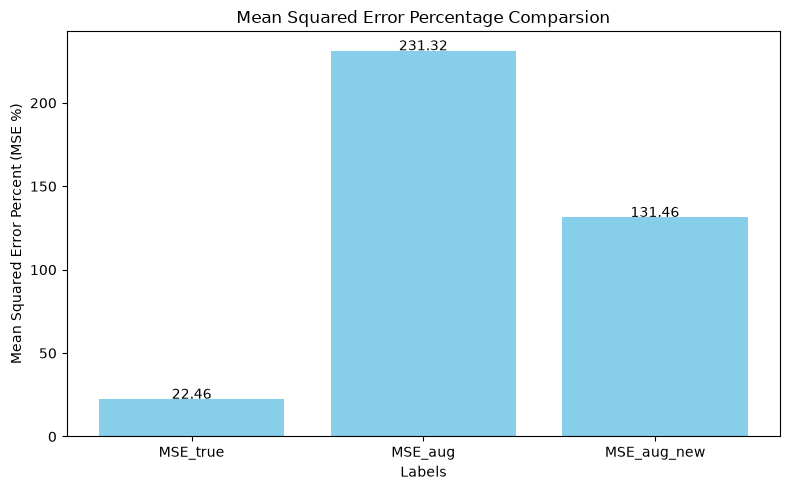

In [40]:
import matplotlib.pyplot as plt

# Example data
MSE_results_labels = ['MSE_true', 'MSE_aug', 'MSE_aug_new']
MSE_results_values = [MSE_true_percentage, MSE_aug_percentage, MSE_aug_new_percentage]

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(MSE_results_labels, MSE_results_values, color='skyblue')

plt.title('Mean Squared Error Percentage Comparsion')
plt.xlabel('Labels')
plt.ylabel('Mean Squared Error Percent (MSE %)')

# Add value labels on bars
for i, values in enumerate(MSE_results_values):
    plt.text(i, values + 0.2, f'{values:.2f}', ha='center')

plt.tight_layout()
plt.show()

## Part 2: Informative metric testing 

In [41]:
import torch
# Reusing the data
X = np.array(df_final.drop(columns="yield_strength"))
y = np.array(df_final["yield_strength"])

X_tensor = torch.tensor(X, dtype=torch.double)
y_tensor = torch.tensor(y, dtype=torch.double)

In [42]:
set_seed(42)
likelihood = gpytorch.likelihoods.GaussianLikelihood()
model = ARDExactGPModel_Dense(train_x=X_tensor,
                              train_y=y_tensor,
                              likelihood=likelihood)

In [43]:
model

ARDExactGPModel_Dense(
  (likelihood): GaussianLikelihood(
    (noise_covar): HomoskedasticNoise(
      (raw_noise_constraint): GreaterThan(1.000E-04)
    )
  )
  (mean_module): ConstantMean()
  (covar_module): ScaleKernel(
    (base_kernel): RBFKernel(
      (raw_lengthscale_constraint): Positive()
    )
    (raw_outputscale_constraint): Positive()
  )
)

In [44]:
set_seed(42)
train_step(X_train=X_tensor,
           y_train=y_tensor,
           model=model,
           likelihood=likelihood)

Iter: 10/100 | Loss: 32198.458 | Noise: 1.282
Iter: 20/100 | Loss: 20152.331 | Noise: 1.896
Iter: 30/100 | Loss: 13531.751 | Noise: 2.382
Iter: 40/100 | Loss: 10650.183 | Noise: 2.714
Iter: 50/100 | Loss: 9104.450 | Noise: 2.935
Iter: 60/100 | Loss: 8180.219 | Noise: 3.098
Iter: 70/100 | Loss: 7551.862 | Noise: 3.231
Iter: 80/100 | Loss: 7062.030 | Noise: 3.351
Iter: 90/100 | Loss: 6677.451 | Noise: 3.460
Iter: 100/100 | Loss: 6369.319 | Noise: 3.564


In [46]:
X_CRDA_tensor, y_CRDA_tensor, _, _ = CRDA_function(X_train=X_tensor,
                                             y_train=y_tensor,
                                             model=model,
                                             likelihood=likelihood)

c:\Users\bandarua\crda_gp\env\Lib\site-packages\gpytorch\models\exact_gp.py:299: GPInputWarning: The input matches the stored training data. Did you forget to call model.train()?
  warnings.warn(


Starting the Loop
Iter: 0
Iter: 1
Iter: 2
Iter: 3
Iter: 4
Iter: 5
Iter: 6
Iter: 7
Iter: 8
Iter: 9
Iter: 10
Iter: 11
Iter: 12
Iter: 13
Iter: 14
Iter: 15
Iter: 16
Iter: 17
Iter: 18
Iter: 19
Iter: 20
Iter: 21
Iter: 22
Iter: 23
Iter: 24
Iter: 25
Iter: 26
Iter: 27
Iter: 28
Iter: 29
Iter: 30
Iter: 31
Iter: 32
Iter: 33
Iter: 34
Iter: 35
Iter: 36
Iter: 37
Iter: 38
Iter: 39
Iter: 40
Iter: 41
Iter: 42
Iter: 43
Iter: 44
Iter: 45
Iter: 46
Iter: 47
Iter: 48
Iter: 49
Iter: 50
Iter: 51
Iter: 52
Iter: 53
Iter: 54
Iter: 55
Iter: 56
Iter: 57
Iter: 58
Iter: 59
Iter: 60
Iter: 61
Iter: 62
Iter: 63
Iter: 64
Iter: 65
Iter: 66
Iter: 67
Iter: 68
Iter: 69
Iter: 70
Iter: 71
Iter: 72
Iter: 73
Iter: 74
Iter: 75
Iter: 76
Iter: 77
Iter: 78
Iter: 79
Iter: 80
Iter: 81
Iter: 82
Iter: 83
Iter: 84
Iter: 85
Iter: 86
Iter: 87
Iter: 88
Iter: 89
Iter: 90
Iter: 91
Iter: 92
Iter: 93
Iter: 94
Iter: 95
Iter: 96
Iter: 97
Iter: 98
Iter: 99
Iter: 100
Iter: 101
Iter: 102
Iter: 103
Iter: 104
Iter: 105
Iter: 106
Iter: 107
Iter: 108
It

In [47]:
from crda_gp.utils import entropy_cal
entropies_true = entropy_cal(X=X_tensor)

In [48]:
entropies_aug = entropy_cal(X=X_CRDA_tensor)

Mean of True vs Aug: 1.7203613881597402 | 1.7195427796772844


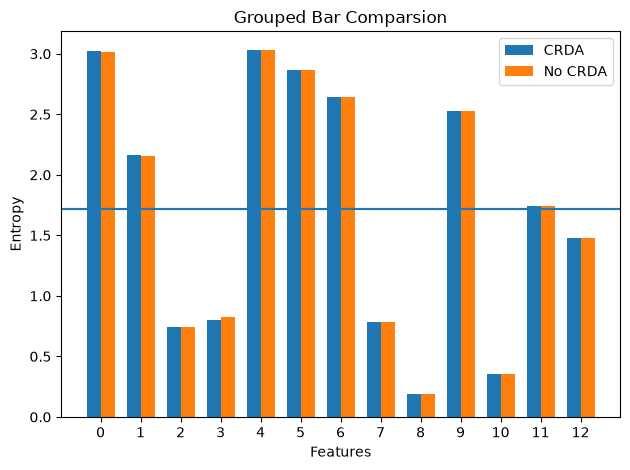

In [49]:
from crda_gp.utils import plot_comparsion_entropies
plot_comparsion_entropies(X_tensor,
                          entropy_1=entropies_aug,
                          entropy_2=entropies_true)

## Part 3: Random Benchmarking vs CRDA 

In [50]:
from crda_gp.crda import random_benchmark
X_random_tensor, y_random_tensor = random_benchmark(X_train=X_train_aug_tensor,
                                                    y_train=y_train_aug_tensor,
                                                    model=model_aug,
                                                    likelihood=likelihood_aug,
                                                    perturb_idx=preturb_idx,
                                                    p=0.1)

Starting the Loop
Iter: 0
Iter: 1
Iter: 2
Iter: 3
Iter: 4
Iter: 5
Iter: 6
Iter: 7
Iter: 8
Iter: 9
Iter: 10
Iter: 11
Iter: 12
Iter: 13
Iter: 14
Iter: 15
Iter: 16
Iter: 17
Iter: 18
Iter: 19
Iter: 20
Iter: 21
Iter: 22
Iter: 23
Iter: 24
Iter: 25
Iter: 26
Iter: 27
Iter: 28
Iter: 29
Iter: 30
Iter: 31
Iter: 32
Iter: 33
Iter: 34
Iter: 35
Iter: 36
Iter: 37
Iter: 38
Iter: 39
Iter: 40
Iter: 41
Iter: 42
Iter: 43
Iter: 44
Iter: 45
Iter: 46
Iter: 47
Iter: 48
Iter: 49
Iter: 50
Iter: 51
Iter: 52
Iter: 53
Iter: 54
Iter: 55
Iter: 56
Iter: 57
Iter: 58
Iter: 59
Iter: 60
Iter: 61
Iter: 62
Iter: 63
Iter: 64
Iter: 65
Iter: 66
Iter: 67
Iter: 68
Iter: 69
Iter: 70
Iter: 71
Iter: 72
Iter: 73
Iter: 74
Iter: 75
Iter: 76
Iter: 77
Iter: 78
Iter: 79
Iter: 80
Iter: 81
Iter: 82
Iter: 83
Iter: 84
Iter: 85
Iter: 86
Iter: 87
Iter: 88
Iter: 89
Iter: 90
Iter: 91


In [51]:
set_seed(42)
likelihood_random = gpytorch.likelihoods.GaussianLikelihood()
model_random = ARDExactGPModel_Dense(train_x=X_random_tensor,
                                     train_y=y_random_tensor,
                                     likelihood=likelihood_random)

In [52]:
set_seed(42)
train_step(X_train=X_random_tensor,
           y_train=y_random_tensor,
           model=model_random,
           likelihood=likelihood_random)

Iter: 10/100 | Loss: 19994.152 | Noise: 1.278
Iter: 20/100 | Loss: 13187.610 | Noise: 1.887
Iter: 30/100 | Loss: 10150.095 | Noise: 2.398
Iter: 40/100 | Loss: 8517.288 | Noise: 2.802
Iter: 50/100 | Loss: 7582.802 | Noise: 3.128
Iter: 60/100 | Loss: 6934.228 | Noise: 3.404
Iter: 70/100 | Loss: 6447.508 | Noise: 3.649
Iter: 80/100 | Loss: 6060.960 | Noise: 3.873
Iter: 90/100 | Loss: 5740.338 | Noise: 4.083
Iter: 100/100 | Loss: 5467.197 | Noise: 4.282


In [53]:
set_seed(42)
y_pred_aug_rand_new = val_step(X_test=X_test_tensor.float(), 
                              model=model_random, 
                              likelihood=likelihood_random)

In [54]:
MSE_aug_rand_new = mean_squared_error(y_test_tensor, y_pred_aug_rand_new)
MSE_aug_rand_new

70051.8828125

In [55]:
MSE_aug_new

48934.5

In [56]:
MSE_aug

70046.46875

In [57]:
MSE_aug_rand_new_percentage = ((MSE_aug_rand_new - MSE_aug)/MSE_aug) * 100
MSE_aug_rand_new_percentage

0.007729244024167885

In [58]:
MSE_aug_new_percentage = ((MSE_aug_new - MSE_aug)/MSE_aug) * 100
MSE_aug_new_percentage

-30.139947276071645

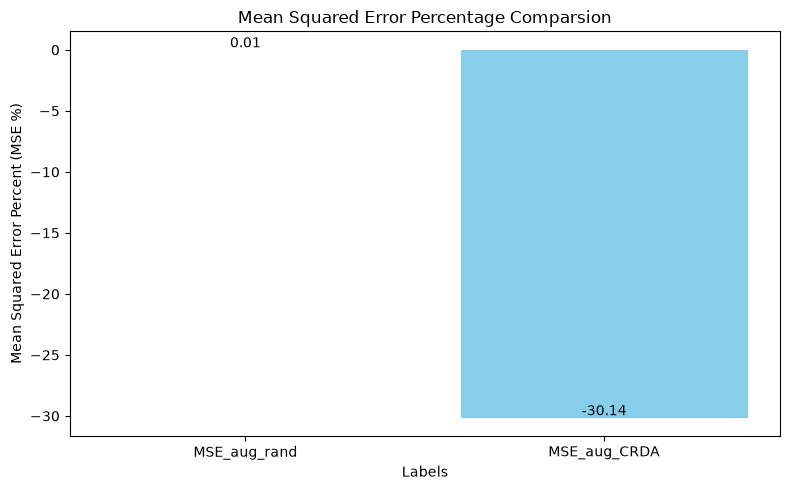

In [59]:
import matplotlib.pyplot as plt

# Example data
MSE_results_labels = ['MSE_aug_rand', 'MSE_aug_CRDA']
MSE_results_values = [MSE_aug_rand_new_percentage, MSE_aug_new_percentage]

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(MSE_results_labels, MSE_results_values, color='skyblue')

plt.title('Mean Squared Error Percentage Comparsion')
plt.xlabel('Labels')
plt.ylabel('Mean Squared Error Percent (MSE %)')

# Add value labels on bars
for i, values in enumerate(MSE_results_values):
    plt.text(i, values + 0.2, f'{values:.2f}', ha='center')

plt.tight_layout()
plt.show()